# DINGO: rotation velocity and inclination from R + C

Sample **deprojected $V_\infty$ and inclination $i$ separately** in one shared arctangent velocity field. Intrinsic dispersion is fixed to zero. PySersic supplies the inclination-prior center; its total Gaussian width is **5°**. No fitted gas-light profile is imposed.

Run settings, imaging, and candidate search; inspect the residuals, choose a candidate, then run MCMC and Results. Use the **grism** kernel. Final files are saved under `WORKING_DIR/ID<source>`.

This uses a **new run name and working directory**. Earlier `rotation_simple_i5_v1` results sampled $V_\infty\sin i$ and are preserved separately. Old candidate numbers do not carry over. No new fit has been run yet.

To reopen a completed fit, run **Results** directly after saving the source/run/candidate settings. To review the whole notebook without fitting, set `RUN_SEARCH = False` and `RUN_MCMC = False`. Let any existing fit finish before starting another job for the same source.


In [3]:
%matplotlib inline
import os
from pathlib import Path
os.environ["JAX_PLATFORMS"] = "cpu"  # Plots on CPU; fitting workers use CUDA.
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dingo import (three_file, three_file_imaging, three_file_plot,
                   three_file_center_plot, three_file_export)
from importlib import reload
for module in (three_file_plot, three_file_center_plot, three_file_export,
               three_file_imaging, three_file):
    reload(module)  # Use the current interface and labels in an existing kernel.

SOURCE_ID = 15665
RUN_NAME = "rotation_v_i5_v1"
WORKING_DIR = Path("/home/aakavan/kinematics/working/rotation_v_i5")

RUN_SEARCH = True       # Fit/reuse PySersic, then find candidate solutions.
RUN_MCMC = True          # Run/resume to DRAWS total; False only displays saved results.
OVERRIDE = False         # True: rebuild this named search and the source's PySersic fit.
VELOCITY_PARAMETER = "V_rot"  # Sample deprojected V_inf and i separately.
INCLINATION_SIGMA_DEG = 5.0  # Total Gaussian 1-sigma width; inclination stays free.
WARMUP = 1000
DRAWS = 8000            # Retained MCMC steps; a short test is not a science error bar.
WALKERS = 64
VELOCITY_RADIUS_PC = None  # None: physical equivalent of 0.5 arcsec, for comparison only.

print("Final results:", WORKING_DIR / f"ID{SOURCE_ID}")
print(f"MCMC enabled: {RUN_MCMC} | Target: {DRAWS:,} retained steps per walker")
print(f"Inclination prior: imaging-derived center, sigma = {INCLINATION_SIGMA_DEG:g} degrees")

print("Sampled velocity: deprojected V_inf [km/s]; inclination i is sampled separately.")


Final results: /home/aakavan/kinematics/working/rotation_v_i5/ID15665
MCMC enabled: True | Target: 8,000 retained steps per walker
Inclination prior: imaging-derived center, sigma = 5 degrees
Sampled velocity: deprojected V_inf [km/s]; inclination i is sampled separately.


**1. Imaging.** Show the F150W image, fit/reuse PySersic, and display its native corner plot. Printed inclinations compare disk thicknesses $q_0=0$ and $0.2$. The gas prior keeps the imaging-derived center and uses `INCLINATION_SIGMA_DEG` as its total Gaussian width, currently **5°**. This is a chosen prior width, not the PySersic measurement error. Inclination remains free between 5° and 85°; ±5° is not a hard interval. Gas brightness and center remain independent.

Using accepted F150W PySersic fits for ID15665: /home/aakavan/kinematics/results/real_sources/ID15665/imaging_runs/pysersic_v1


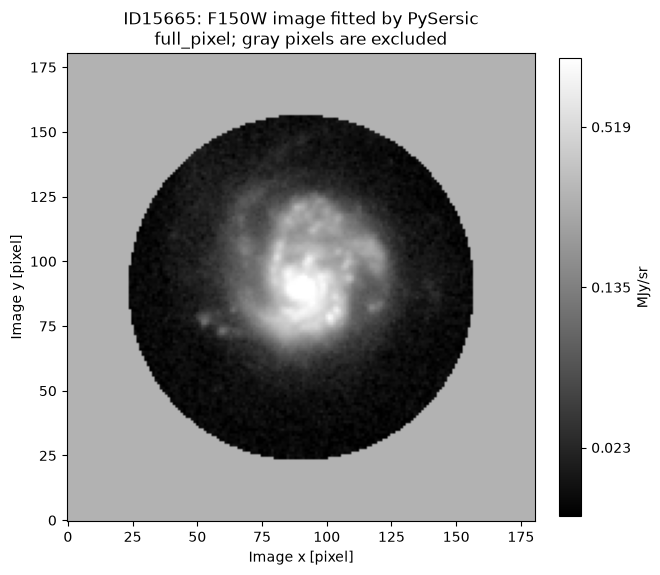

,fit,completed,ready,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,q_median,residual_RMS,parameter_checks_passed,note
0,full_pixel,True,True,1.001446,4211.056911,4707.834954,0,0.869868,4.782558,True,Inspect residuals; passing sampler checks does...
1,core_pixel_clean,True,True,1.002491,5763.189318,4948.144040,0,0.834769,4.302802,True,Inspect residuals; passing sampler checks does...


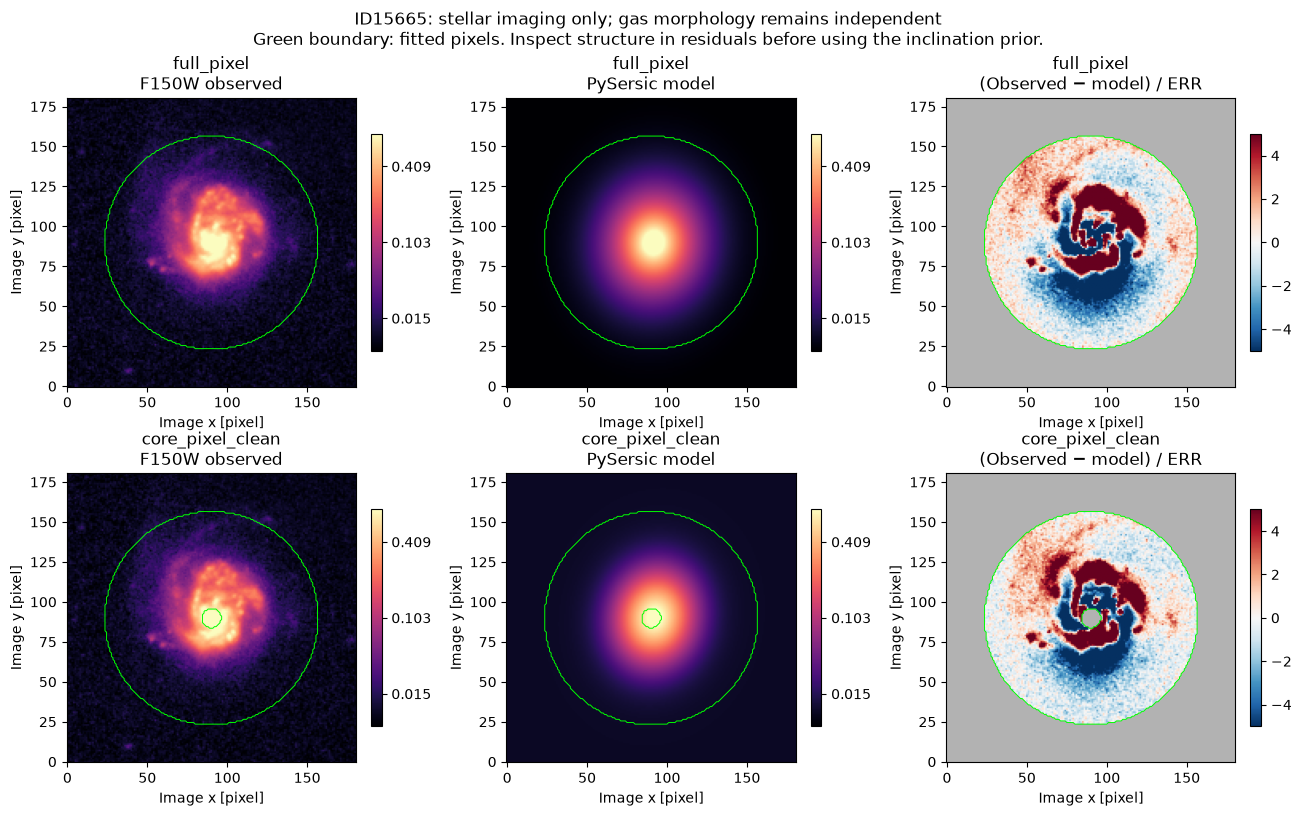

full_pixel: native PySersic parameters.


,meaning,median,minus_1sigma,plus_1sigma,p16,p84,unit
parameter,,,,,,,
xc,Center x,91.660187,0.007335,0.006990,91.652852,91.667177,pixel
yc,Center y,89.780083,0.007390,0.007193,89.772693,89.787276,pixel
flux,Total Sérsic flux,175331.045630,708.710621,730.462592,174622.335009,176061.508222,normalized image sum
r_eff,Effective radius,20.777153,0.092321,0.099939,20.684831,20.877092,pixel
n,Sérsic index,1.740610,0.009591,0.009948,1.731019,1.750559,
ellip,Ellipticity = 1 − b/a,0.130132,0.001046,0.001051,0.129085,0.131183,
theta,PySersic angle,2.991976,0.004445,0.004447,2.987531,2.996422,rad
sky_back,Constant sky level,-1.497395,0.030010,0.029007,-1.527404,-1.468388,normalized image value
q,Axis ratio b/a (derived),0.869868,0.001051,0.001046,0.868817,0.870915,


Derived stellar inclination: median and 16th–84th percentile interval; fixed disk thickness, before stellar–gas scatter.
  q0 = 0: i = 29.557 (+0.122/−0.122) deg
  q0 = 0.2: i = 30.229 (+0.125/−0.125) deg


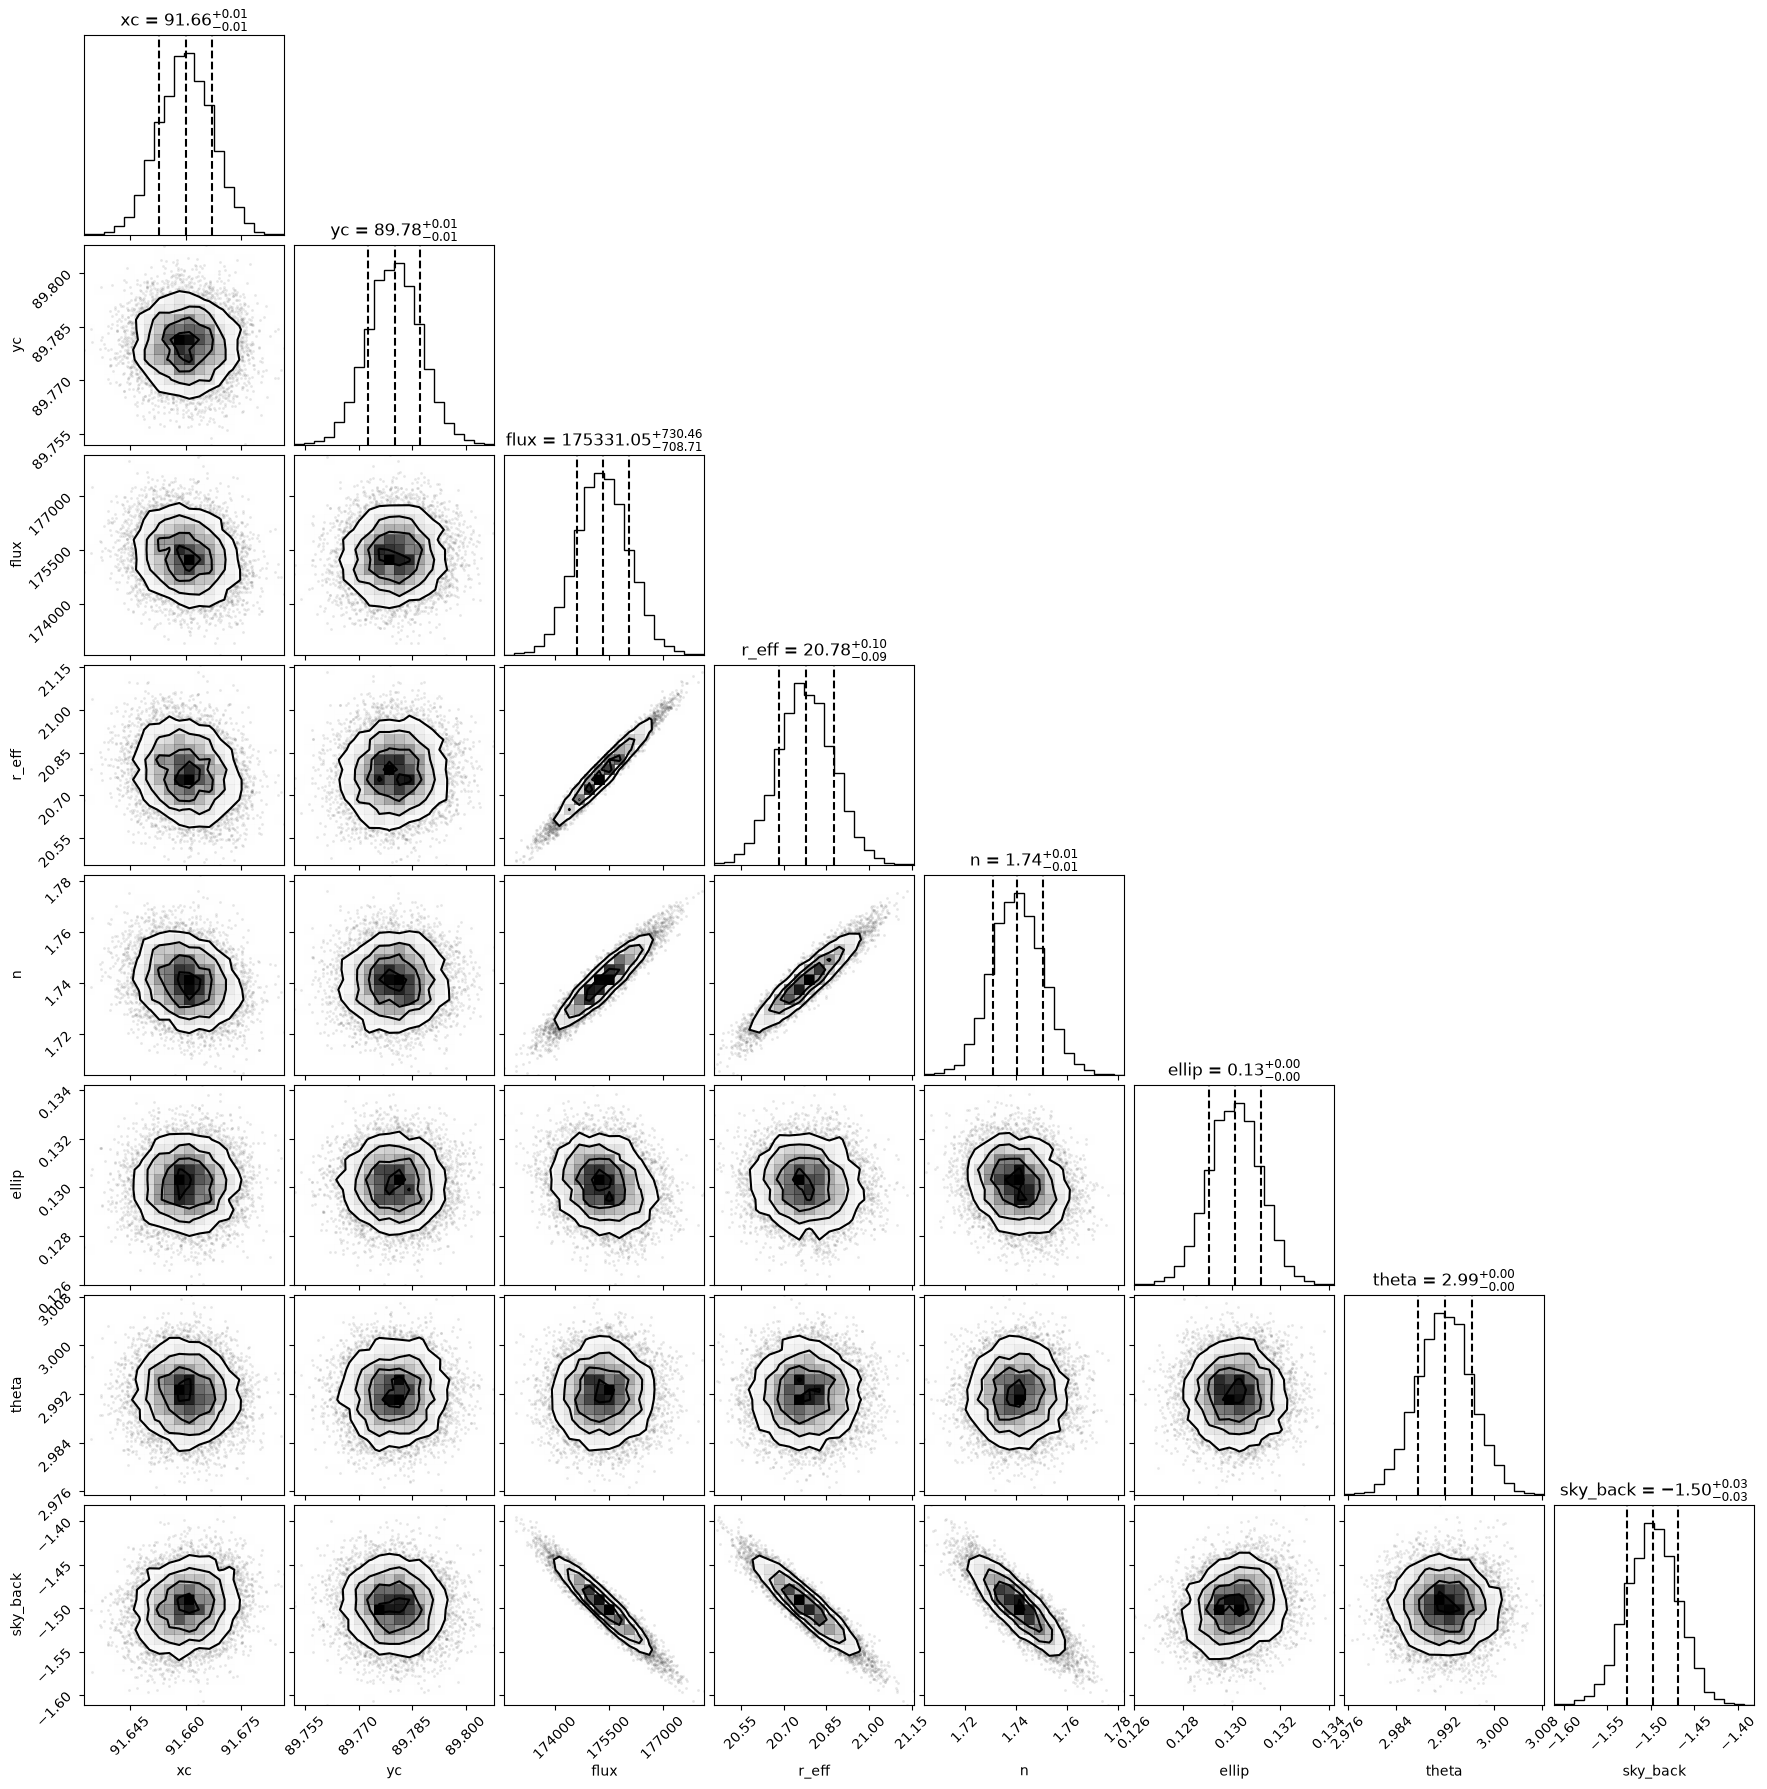

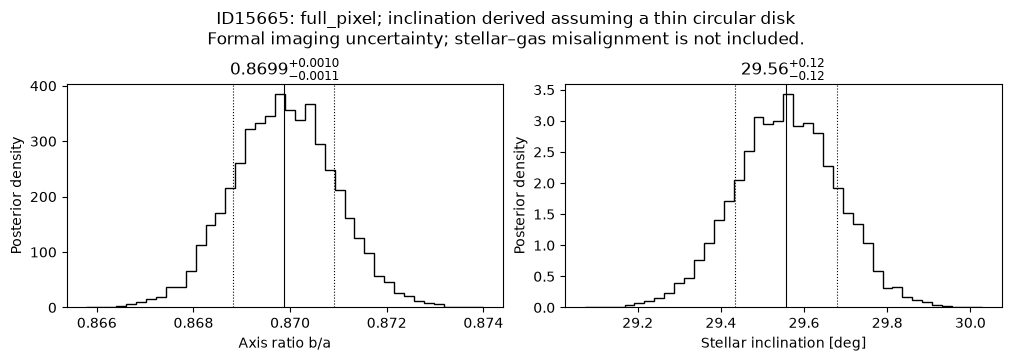

The imaging fit does not fix the gas center or gas-emission shape. Using its inclination in the velocity fit is a separate choice.
Gas inclination prior: Gaussian 32.1 ± 5.0 degrees, truncated to 5–85°.


In [4]:
from dingo.three_file_imaging import review_imaging, inclination_prior

imaging_result = None
imaging_prior_record = None
try:
    imaging_result = review_imaging(SOURCE_ID, run=RUN_SEARCH, override=OVERRIDE)
except FileNotFoundError:
    if RUN_SEARCH:
        raise
    print("No saved imaging to display; the saved search keeps its original prior.")

if RUN_SEARCH and imaging_result is not None:
    imaging_prior_record = inclination_prior(imaging_result, total_sigma_deg=INCLINATION_SIGMA_DEG)
    print("Gas inclination prior: Gaussian "
          f"{imaging_prior_record['inclination_deg']:.1f} ± "
          f"{imaging_prior_record['inclination_sigma_deg']:.1f} degrees, truncated to 5–85°.")


**2. Find and inspect candidates.** Search over deprojected velocity and disk geometry, then inspect every candidate on matching image scales. The table and residual labels distinguish the sampled asymptotic $V_\infty$ from $V(r)$ at the comparison radius. $V_\infty\sin i$ is derived. Candidate IDs belong only to this search.


In [19]:
result = None
candidates = None
if RUN_SEARCH:
    if (imaging_prior_record is None or
            imaging_prior_record["source_id"] != three_file.source_number(SOURCE_ID)):
        raise RuntimeError("Run the PySersic block for this source before searching.")
    candidates = three_file.search(
        SOURCE_ID, run_name=RUN_NAME, override=OVERRIDE,
        inclination_deg=imaging_prior_record["inclination_deg"],
        inclination_sigma_deg=imaging_prior_record["inclination_sigma_deg"],
        inclination_metadata=imaging_prior_record,
        search_method="broad", n_candidates=8, velocity_parameter=VELOCITY_PARAMETER,
        profile_radius_pc=VELOCITY_RADIUS_PC,
    )
else:
    candidates = three_file.load_candidates(SOURCE_ID, run_name=RUN_NAME)


ID6084: image.fits + R.fits + C.fits; intrinsic dispersion = 0.
Sampled velocity: V_rot; inclination is sampled separately.
Search and display candidate residuals; no MCMC.
Progress and checkpoints: /home/aakavan/kinematics/results/three_file_sources/ID6084/rotation_v_i5_v1
OVERRIDE=True: starting a fresh run in /home/aakavan/kinematics/results/three_file_sources/ID6084/rotation_v_i5_v1
23:08:20 | Sampling definition: V_rot is deprojected asymptotic rotation speed; V_sini=V_rot*sin(i) is derived; uniform amplitude support 0..1500 km/s.
23:08:20 | [KinematicsFitter] using coordinate unit = pix
23:08:20 | [KinematicsFitter] image.R.cutout derived as (449, 9, 41, 41) from summary.r_fit=20 and z=5.7174 (an explicit cutout would go stale if z were corrected)
23:08:20 | [KinematicsFitter] image.C.cutout derived as (29, -490, 41, 41) from summary.r_fit=20 and z=5.7174 (an explicit cutout would go stale if z were corrected)
23:08:20 | [MCMC] noise model frozen: sigma_R=0.003633 sigma_C=0.00582

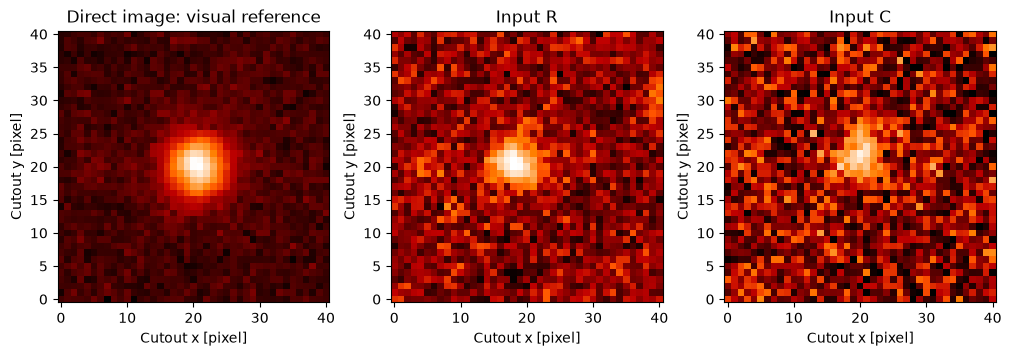

This saved search samples V_rot; Vinf is the asymptote, Vrot_at_radius is the speed at the listed radius.


,Vinf_kms,inclination_deg,Vrot_at_radius_kms,radius_pc,Vinf_sin_i_kms,turnover_pc,kind,twice_delta_log_posterior
candidate,,,,,,,,
0,252.097543,27.393939,242.000000,2995.393993,115.991558,188.709822,free candidate,0.000000
1,283.349304,24.065814,272.000000,2995.393993,115.545804,188.709822,free candidate,0.617533
2,260.431346,26.393939,250.000000,2995.393993,115.772260,188.709822,free candidate,1.229822
3,215.376327,32.675189,206.749620,2995.393993,116.276481,188.709822,free candidate,1.695116
4,312.517615,21.698626,300.000000,2995.393993,115.545413,188.709822,free candidate,1.773978
5,312.517615,21.659564,300.000000,2995.393993,115.347419,188.709822,free candidate,2.856522
6,338.560750,19.972064,325.000000,2995.393993,115.639463,188.709822,free candidate,3.270329
7,222.656250,31.526751,213.737952,2995.393993,116.426197,188.709822,free candidate,3.812081
8,619.755670,11.214251,550.000000,2995.393993,120.529055,535.169260,fixed-velocity comparison; free MCMC can move,41.201217


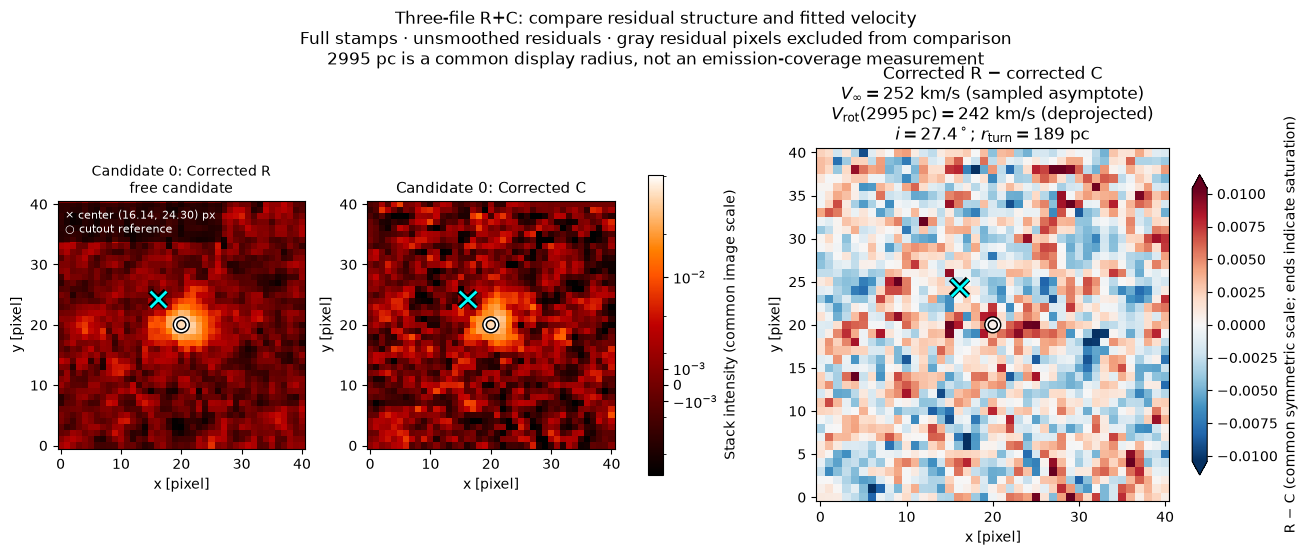

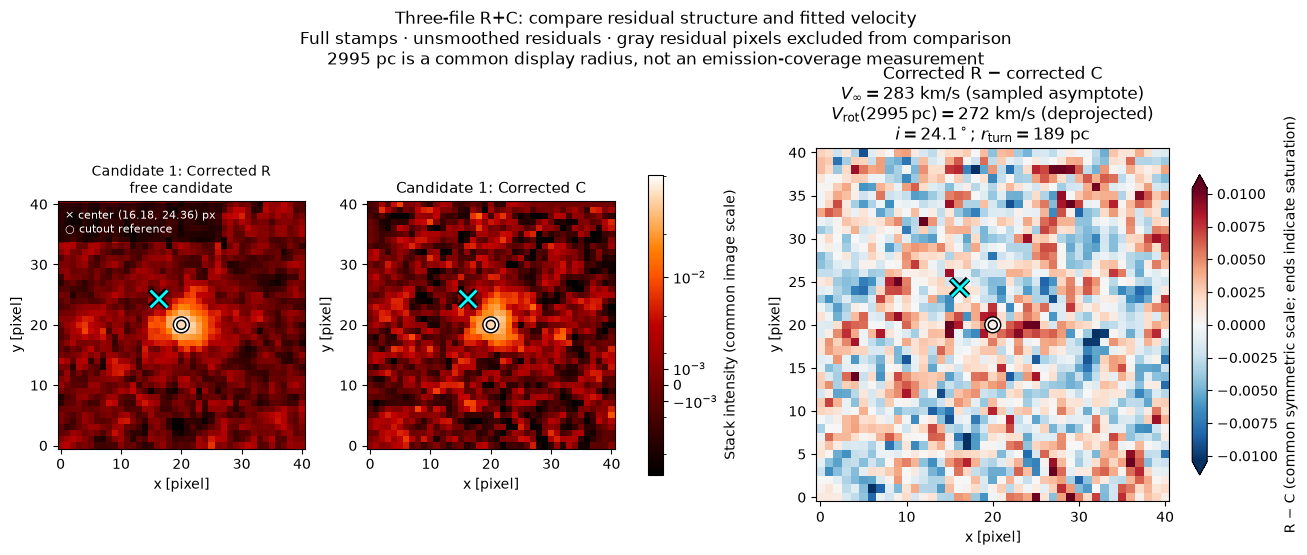

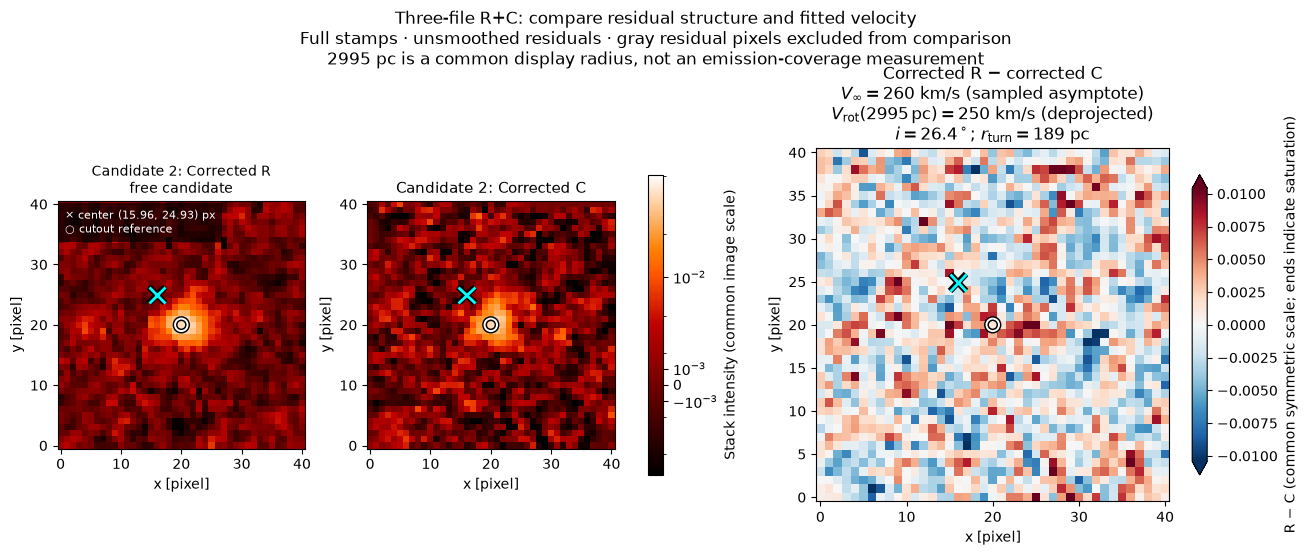

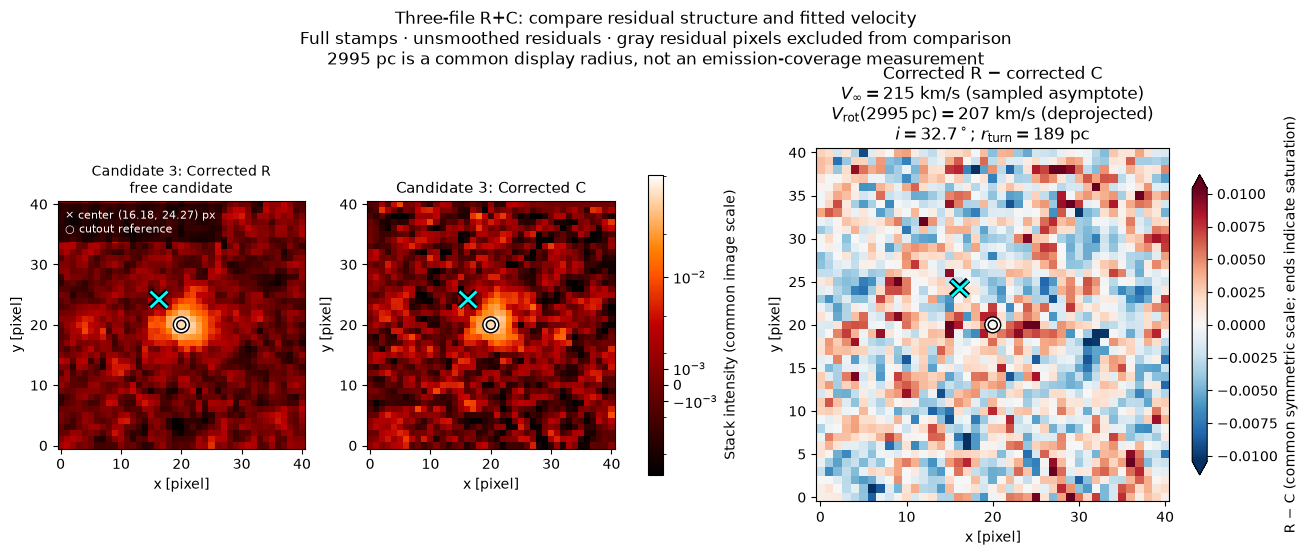

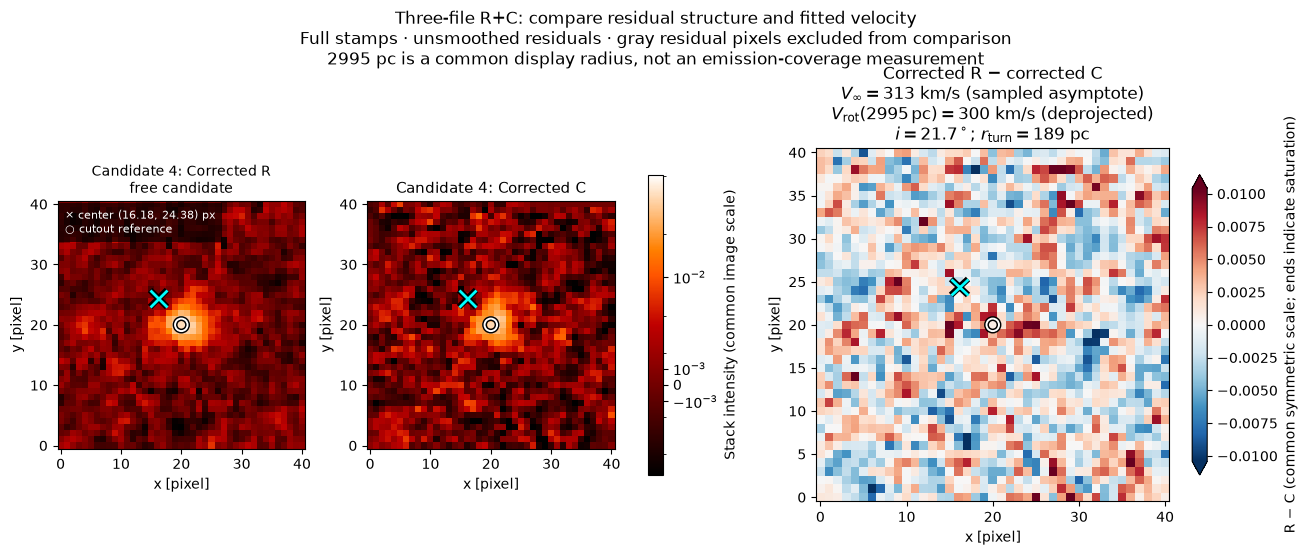

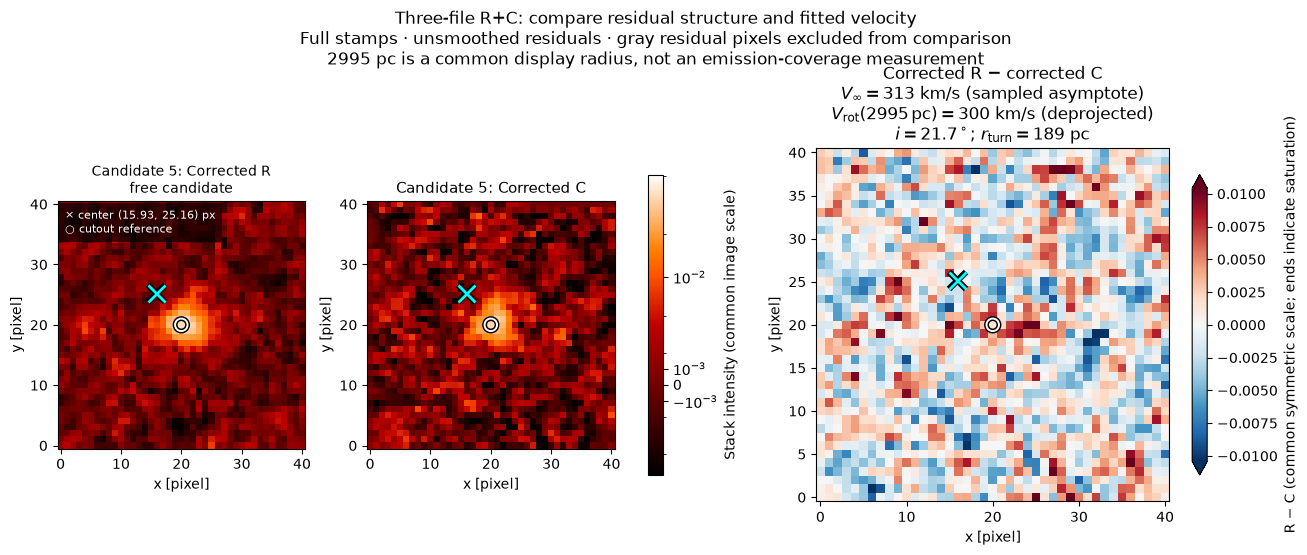

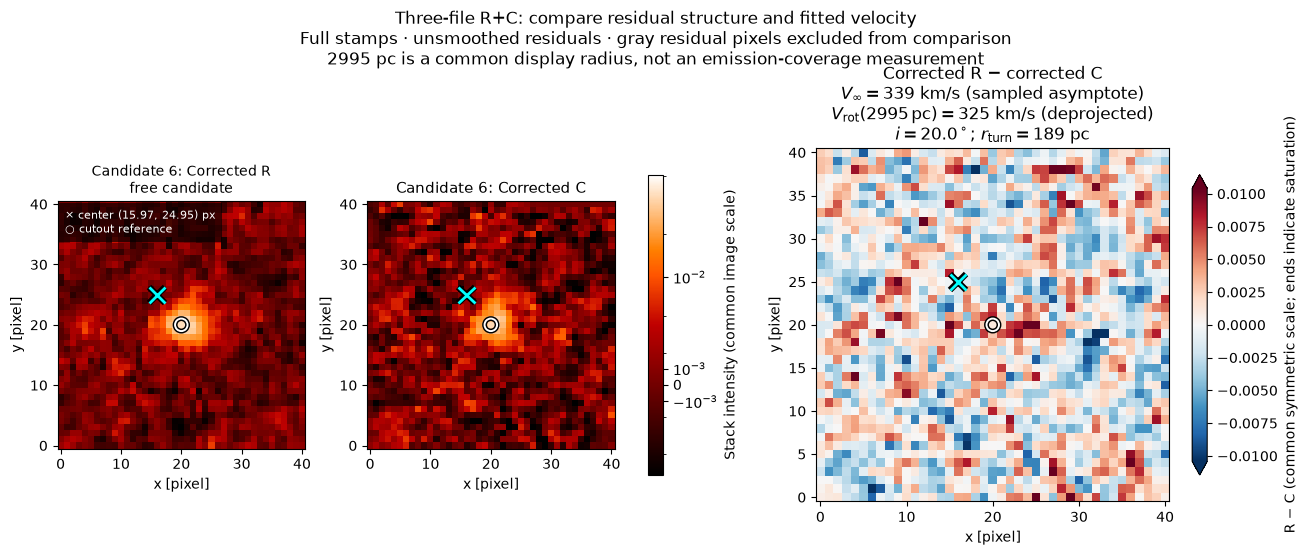

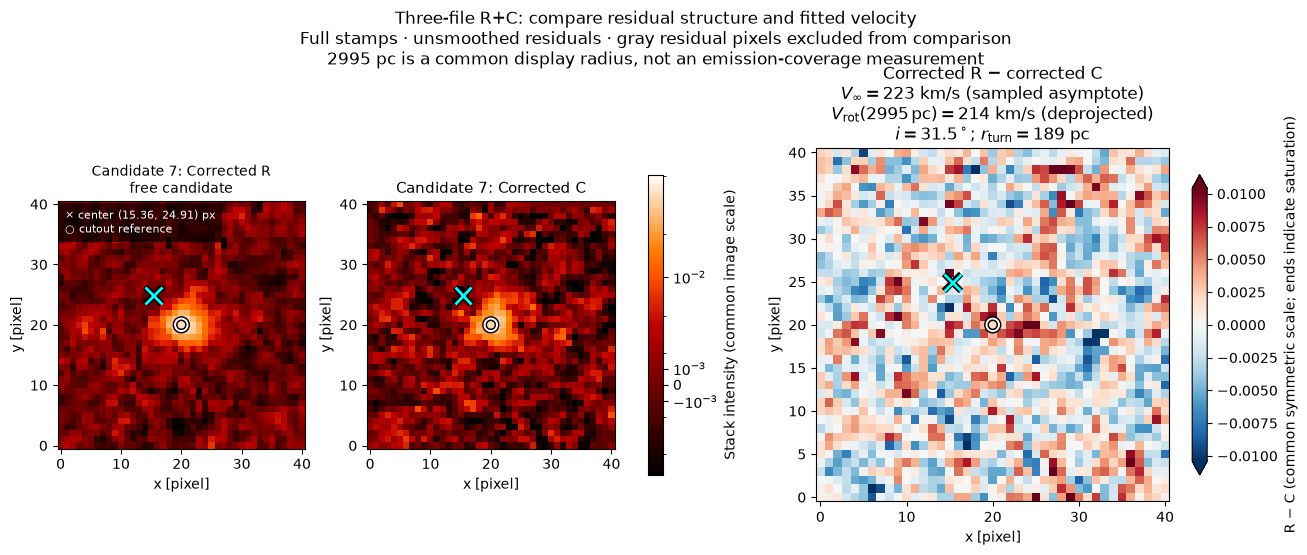

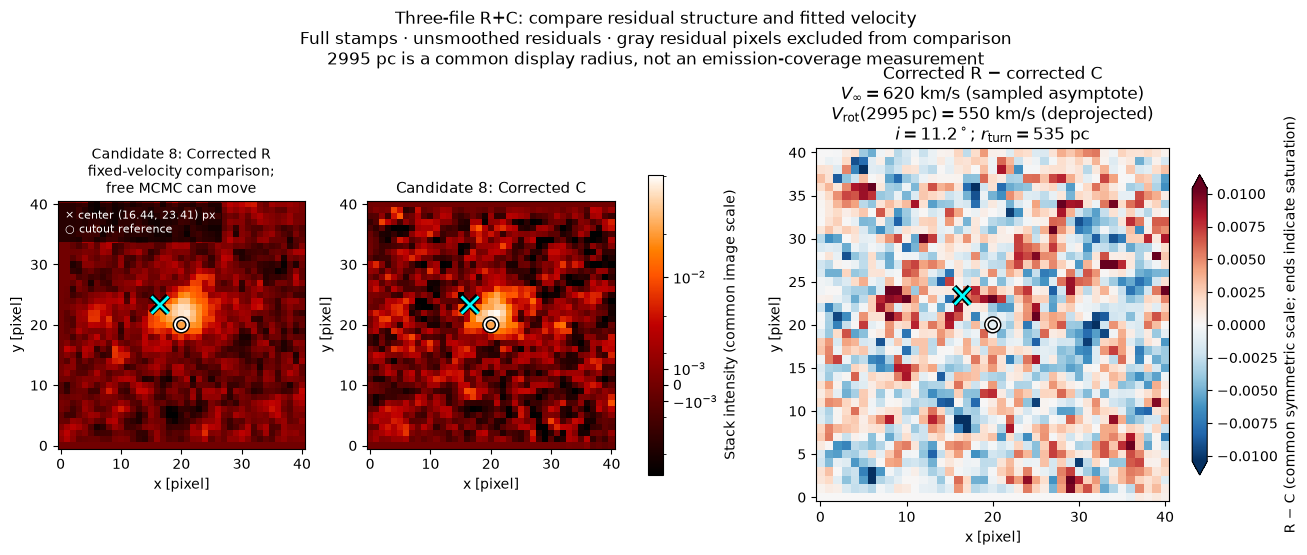

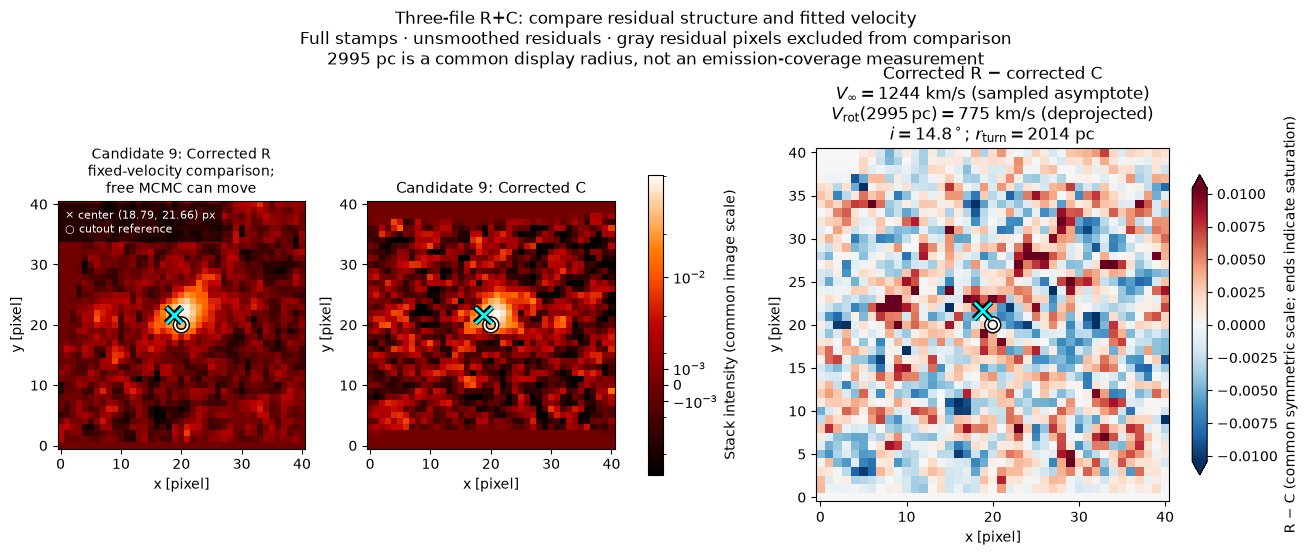

Scores use one fixed comparison model. Fixed-velocity rows are constrained comparisons; free MCMC can move.
The last profile cross-check still improved some points; treat the curve as a finite search, not a certified global optimum.


In [20]:
# Display saved candidates only; rerunning this cell does not refit.
from importlib import reload
from dingo import three_file_plot
reload(three_file_plot)  # Keep plot velocity labels consistent with the table.
candidates = three_file.load_candidates(SOURCE_ID, run_name=RUN_NAME)
fig = candidates.input_figure()
display(fig)
plt.close(fig)

print(f"This saved search samples {candidates.velocity_parameter}; "
      "Vinf is the asymptote, Vrot_at_radius is the speed at the listed radius.")
table = candidates.table(radius_pc=VELOCITY_RADIUS_PC)
columns = (["Vinf_kms", "inclination_deg", "Vrot_at_radius_kms", "radius_pc", "Vinf_sin_i_kms"]
           if candidates.velocity_parameter == "V_rot" else
           ["Vsin_i_at_radius_kms", "radius_pc", "Vinf_sin_i_kms", "inclination_deg"])
columns += ["turnover_pc", "kind", "twice_delta_log_posterior"]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(table[[name for name in columns if name in table]])
for candidate_id in candidates.candidate_ids:
    fig = candidates.figure(candidate_ids=[candidate_id], radius_pc=VELOCITY_RADIUS_PC)
    display(fig)
    plt.close(fig)
print(candidates.search_notes())


**3. MCMC.** Choose a candidate from this search. The sampler varies **$V_\infty$ and $i$ as two separate parameters**, together with turnover radius, center, orientation, R/C registration and noise scale. The inclination prior is Gaussian with the imaging-derived mean and **5° total 1σ width**, truncated to 5–85°. The velocity prior is uniform from 0 to 1500 km/s in **deprojected $V_\infty$**. MCMC may move away from the starting candidate. Progress and checkpoints are automatic; this cell preserves the candidate search.


In [21]:
CANDIDATE_ID = 8  # Choose from this new search; old candidate numbers do not carry over.

# A fresh kernel has no settings yet; do not infer permission to start MCMC.
result = None
required_settings = ("SOURCE_ID", "RUN_NAME", "RUN_MCMC", "WARMUP", "DRAWS",
                     "WALKERS", "WORKING_DIR", "VELOCITY_RADIUS_PC", "VELOCITY_PARAMETER", "three_file")
if any(name not in globals() for name in required_settings):
    raise RuntimeError("Run the settings cell at the top before starting MCMC. "
                       "To view a completed fit, run the Results cell directly instead.")

def load_selected_posterior():
    if CANDIDATE_ID is not None:
        return three_file.load(SOURCE_ID, run_name=RUN_NAME, candidate_id=CANDIDATE_ID)
    return None

result = None
if CANDIDATE_ID is None:
    print("Choose a candidate above, then rerun this cell and those below.")
elif RUN_MCMC:
    saved_prior = three_file.load_candidates(SOURCE_ID, run_name=RUN_NAME).inclination_settings()
    result = three_file.fit(
        SOURCE_ID, run_name=RUN_NAME, candidate_id=CANDIDATE_ID,
        warmup=WARMUP, samples=DRAWS, walkers=WALKERS,
        override=False, velocity_parameter=VELOCITY_PARAMETER, **saved_prior,
    )
else:
    print("RUN_MCMC=False: loading saved results only; no MCMC steps are being added.", flush=True)
    from dingo.notebook_results import load_for_review
    result, _ = load_for_review(globals())

if result is not None:
    print(result.status)
    if result.report.get("status") == "complete":
        final_directory = result.export(WORKING_DIR, radius_pc=VELOCITY_RADIUS_PC)
        print("Final files:", final_directory)


ID6084: image.fits + R.fits + C.fits; intrinsic dispersion = 0.
Sampled velocity: V_rot; inclination is sampled separately.
Selected candidate 8; 64 walkers × 1,000 burn-in + 8,000 retained steps.
Progress and checkpoints: /home/aakavan/kinematics/results/three_file_sources/ID6084/rotation_v_i5_v1
23:12:16 | Sampling definition: V_rot is deprojected asymptotic rotation speed; V_sini=V_rot*sin(i) is derived; uniform amplitude support 0..1500 km/s.
23:12:16 | Reusing completed broad search.
23:12:16 | [SharedComparisonFitter] using coordinate unit = pix
23:12:16 | [SharedComparisonFitter] image.R.cutout derived as (449, 9, 41, 41) from summary.r_fit=20 and z=5.7174 (an explicit cutout would go stale if z were corrected)
23:12:16 | [SharedComparisonFitter] image.C.cutout derived as (29, -490, 41, 41) from summary.r_fit=20 and z=5.7174 (an explicit cutout would go stale if z were corrected)
23:12:16 | Chosen candidate 8: sampled V_rot=619.8 km/s, V_inf=619.8 km/s, R_v=1.418 px, inverse R-C

**4. Results.** These cells only read saved fits and can run after a kernel restart; save edited source/run/candidate settings first. Cyan × marks the fitted center; white ○ is the cutout reference. The direct-image overlay assumes nominal stack alignment. For this run, corners and traces lead with **sampled deprojected $V_\infty$**, and show the separately sampled $i$. Corner titles show pooled medians and 16th–84th percentiles. Errors remain conditional on the chosen model and approximate stacked-image noise treatment. Agreement within one solution does not establish agreement between different candidate solutions. Center axes show pixel offsets $x_0-x_{\rm cut}$ and $y_0-y_{\rm cut}$: zero is the full-cutout center: (40, 40) for an 81 × 81 stamp, or (20, 20) for a 41 × 41 stamp. The image overlays use absolute zero-based pixel coordinates.

ID6084 | three-file DINGO | complete
64 ensemble walkers × 8000 retained steps; σ₀ = 0.
MCMC initialized at candidate 8; inspect any movement from that solution.
Sampling-length checks passed; errors use the approximate stacked-image noise model.
/home/aakavan/kinematics/results/three_file_sources/ID6084/rotation_v_i5_v1
Saved sampled velocity parameter: V_rot


,median,minus_1sigma,plus_1sigma
parameter,,,
Vinf [km/s],115.569213,16.304596,25.048238
Vrot(2995 pc) [km/s],109.012350,15.403255,23.792849
Inclination [deg],24.483201,4.597469,4.332324
Vrot(2995 pc) sin(i) [km/s],45.267181,2.174757,2.234716
Vinf sin(i) [km/s],47.960415,2.299684,2.406800


,parameter,autocorrelation_steps,retained_steps_per_autocorrelation,effective_samples,split_half_shift
0,velocity.V_rot,140.228375,57.049794,3651.186846,0.092587
1,velocity.R_v,96.693987,82.735238,5295.055224,0.010378
2,velocity.x0_v,83.598556,95.695433,6124.507719,0.054494
3,velocity.y0_v,75.248031,106.315075,6804.164792,0.039664
4,velocity.theta_v,71.512862,111.867988,7159.551247,0.046641
5,velocity.inc_v,113.498631,70.485432,4511.067634,0.031378
6,image.R.dx,62.530088,127.938409,8188.058157,0.030076
7,image.R.dy,62.974491,127.035564,8130.276097,0.007693
8,noise.ln_f,58.317720,137.179575,8779.492802,0.017243


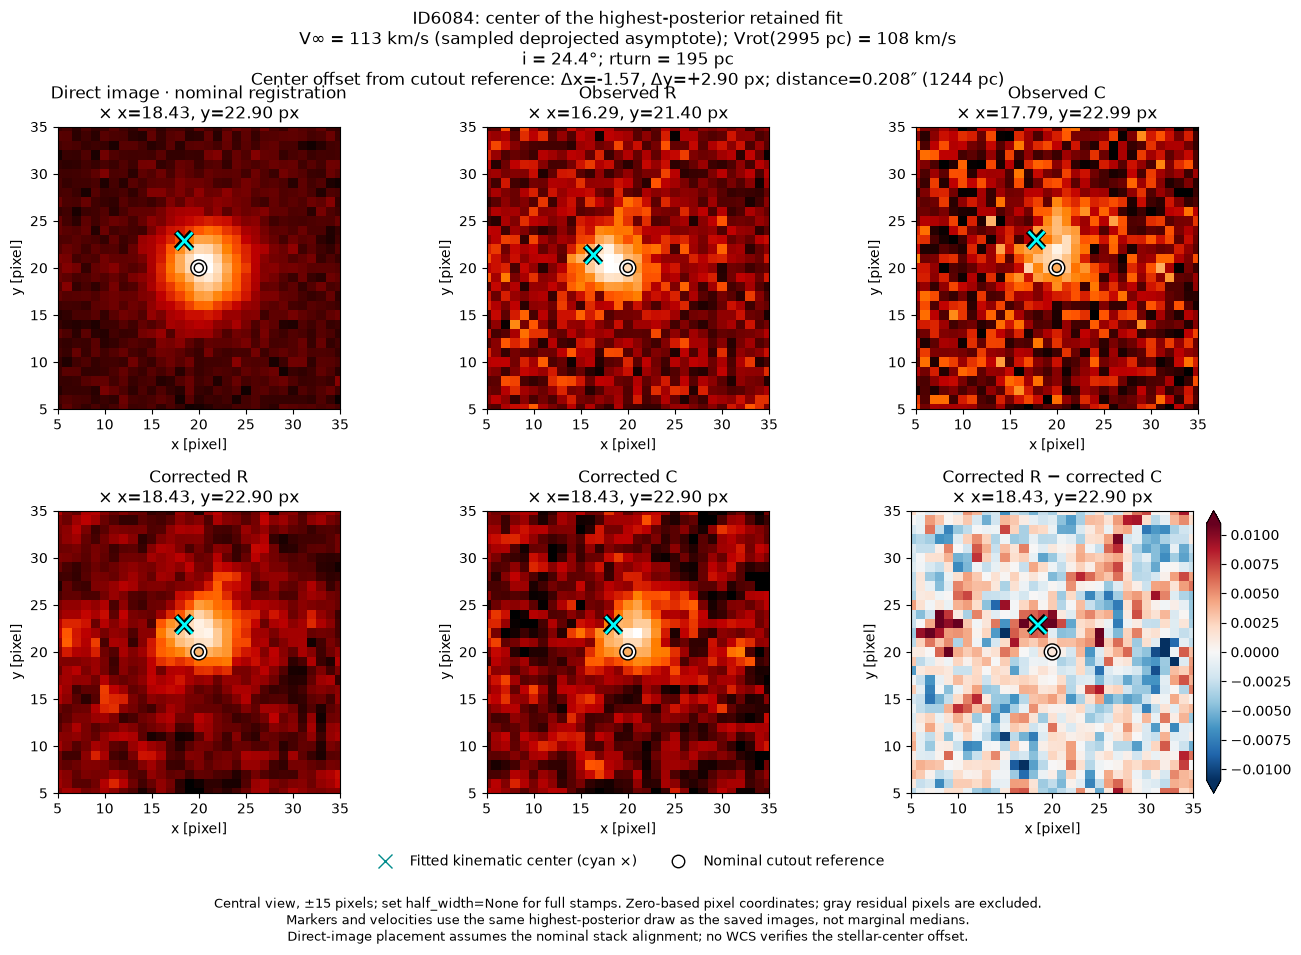

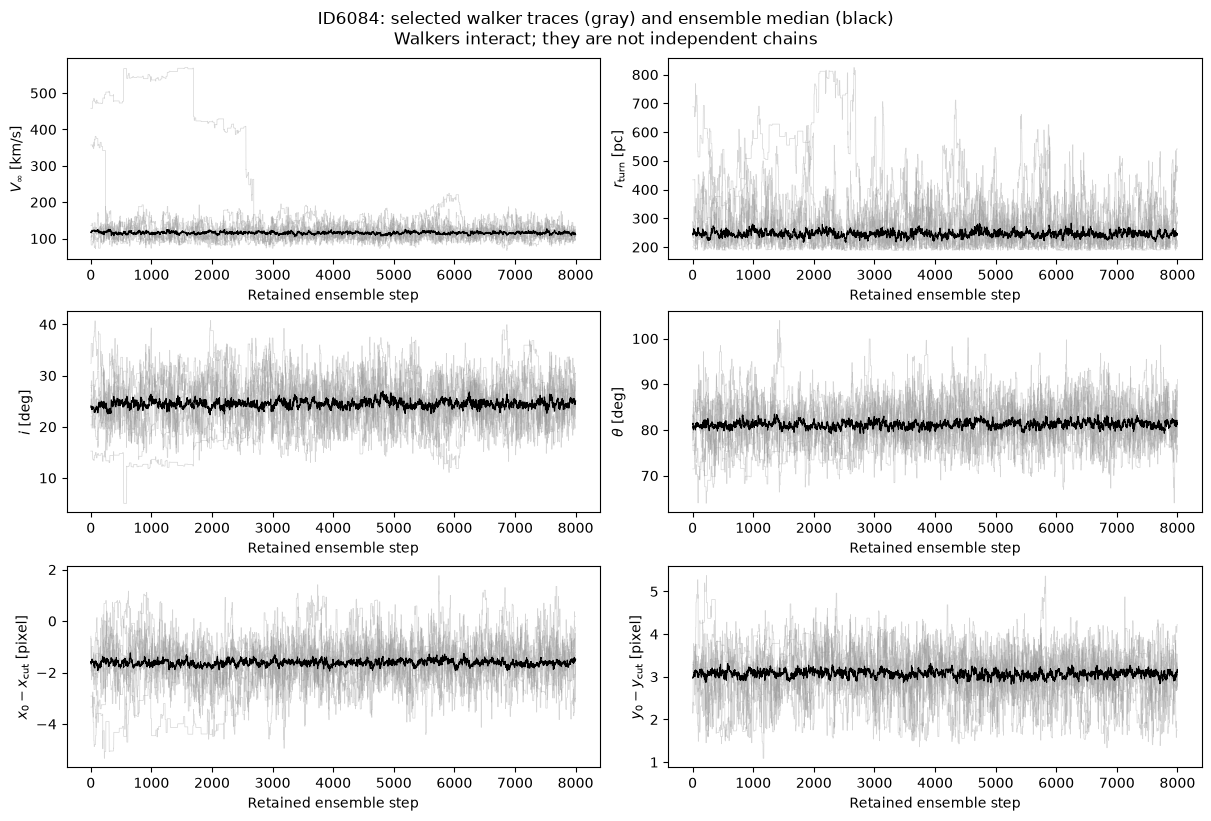

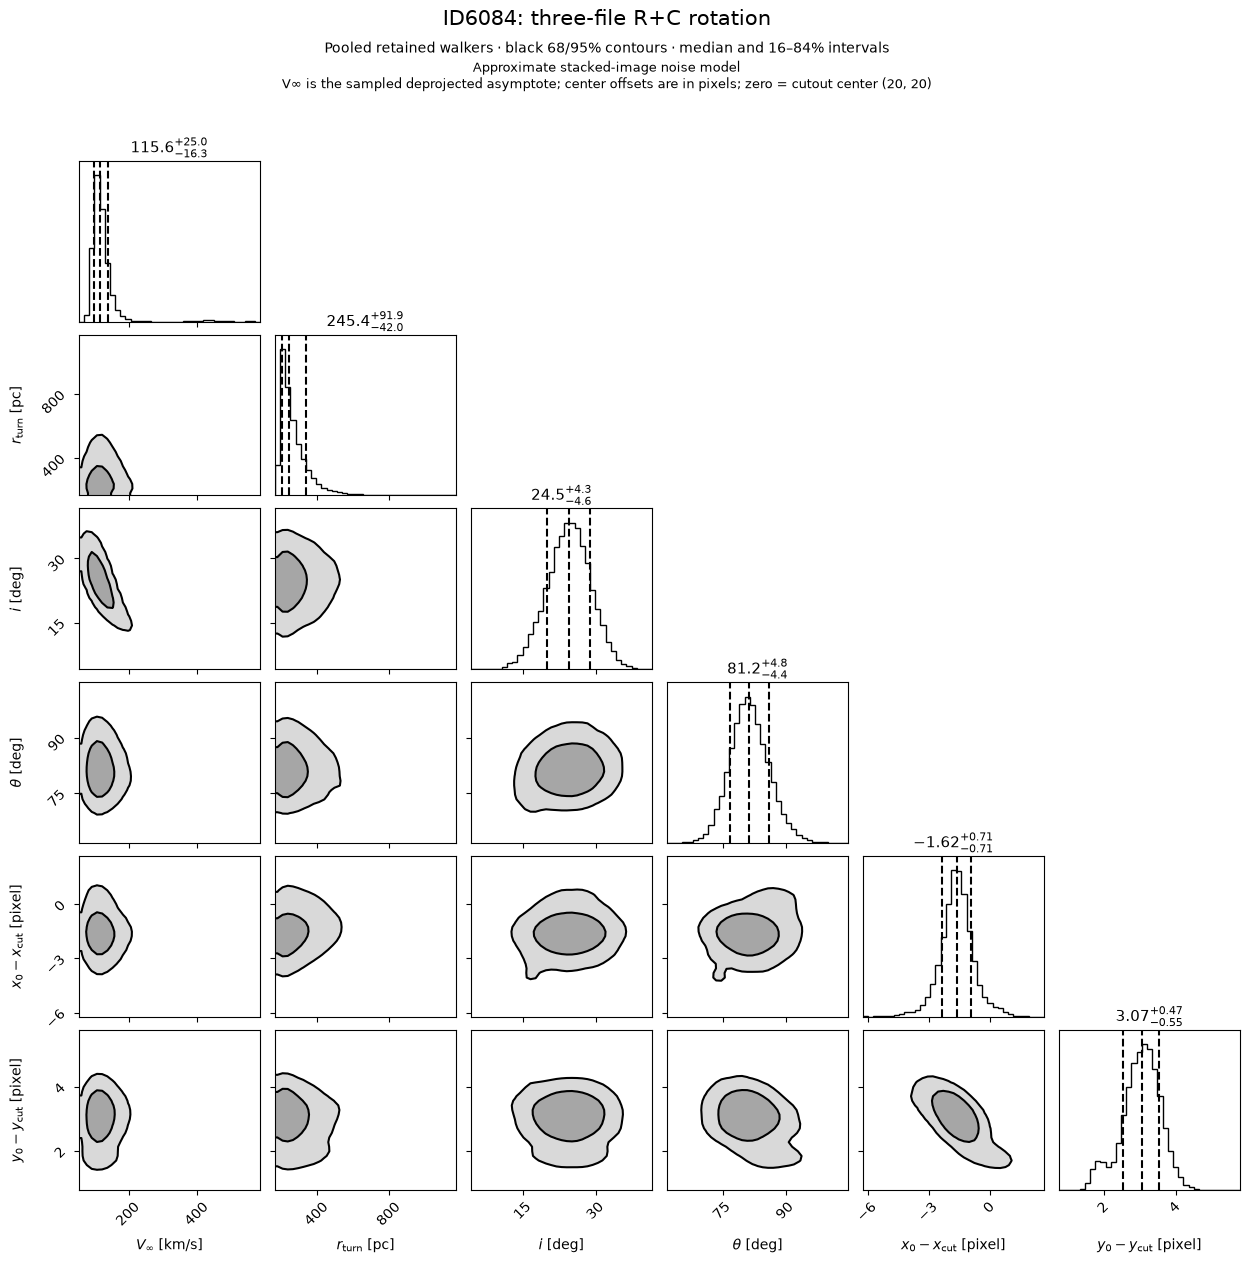

In [22]:
from importlib import reload
from dingo import three_file, three_file_plot, three_file_center_plot
reload(three_file_center_plot)
reload(three_file_plot)
reload(three_file)  # Use current plotting code even in an older kernel.
from dingo.notebook_results import load_for_review
from dingo.three_file_center_plot import review_center
from IPython.display import display
import matplotlib.pyplot as plt

result = None
result, radius_pc = load_for_review(globals())
if result is not None:
    print(result.status)
    print("Saved sampled velocity parameter:", result.velocity_parameter)
    display(result.velocity_summary(radius_pc=radius_pc))
    display(result.diagnostics())
    fig = review_center(result, radius_pc=radius_pc, half_width=15.)
    display(fig)
    plt.close(fig)
    for plot in (result.traces, result.corner):
        fig = plot()
        display(fig)
        plt.close(fig)


**Rotation curve.** $V(r)=(2/\pi)V_\infty\arctan(r/R_v)$. This run displays the deprojected curve from paired posterior draws. The radius range is illustrative, not an established emission extent. The mass interpretation can be considered later.


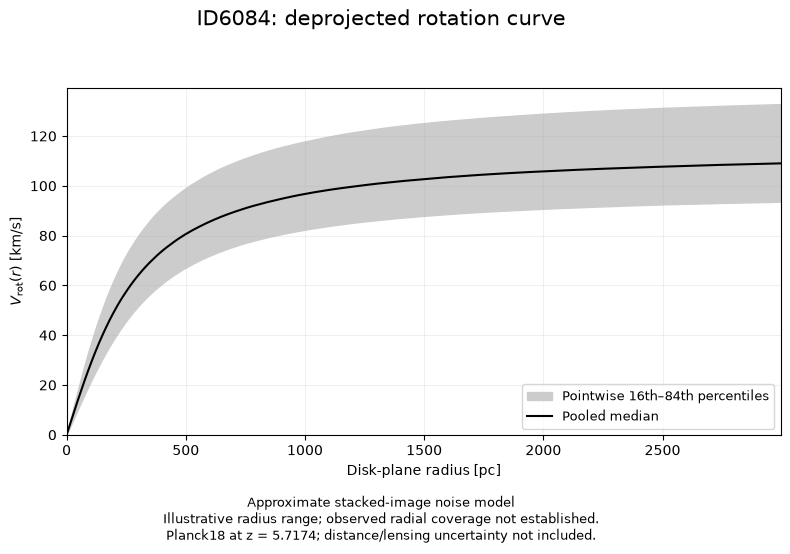

In [23]:
from dingo.notebook_results import load_for_review
from IPython.display import display
import matplotlib.pyplot as plt

result = None
result, radius_pc = load_for_review(globals())
if result is not None:
    fig = result.rotation_curve()
    display(fig)
    plt.close(fig)
